In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
def preparer_donnees_rte(chemin_fichier):

    df = pd.read_csv(chemin_fichier)

    col_date = 'date_heure_utc'

    df[col_date] = pd.to_datetime(df[col_date], utc=True)

    df[col_date] = df[col_date].dt.tz_convert('Europe/Paris')

    df = df.set_index(col_date)
    df = df.sort_index()

    df['Annee'] = df.index.year
    df['Mois'] = df.index.month
    df['Jour_semaine'] = df.index.day_of_week
    df['Heure'] = df.index.hour
    return df

chemin = "data/df_rte.csv"

df_rte = preparer_donnees_rte(chemin)

df_rte.head()



,consommation,solaire,eolien,nucleaire,hydraulique,gaz,ech_physiques,charge_residuelle_mw,Annee,Mois,Jour_semaine,Heure
date_heure_utc,,,,,,,,,,,,
2020-01-01 01:00:00+01:00,63943.0,-1.0,3203.0,48970.0,9133.0,6257.0,-4889.0,60741.0,2020,1,2,1
2020-01-01 01:15:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,1
2020-01-01 01:30:00+01:00,63904.0,-1.0,2981.0,49648.0,9124.0,5630.0,-4736.0,60924.0,2020,1,2,1
2020-01-01 01:45:00+01:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020,1,2,1
2020-01-01 02:00:00+01:00,63408.0,-1.0,2799.0,49764.0,8699.0,5337.0,-4464.0,60610.0,2020,1,2,2


## Nettoyage des valeurs manquantes
En affichant les premières lignes du tableau, on remarque que les pas de temps de 15 et 45 minutes sont remplis de valeurs manquantes (`NaN`) pour les variables principales. Nous allons nettoyer la base en supprimant ces lignes inutiles pour obtenir un pas de temps régulier à la demi-heure.

In [15]:
# On supprime les lignes où la colonne 'consommation' est manquante (NaN)
df_rte_clean = df_rte.dropna(subset=['consommation'])

# On vérifie l'impact du nettoyage
print(f"Nombre de lignes avant nettoyage : {len(df_rte)}")
print(f"Nombre de lignes après nettoyage : {len(df_rte_clean)}")

# On affiche les 5 premières lignes pour confirmer la disparition des :15 et :45
df_rte_clean.head()

Nombre de lignes avant nettoyage : 210408
Nombre de lignes après nettoyage : 105203


,consommation,solaire,eolien,nucleaire,hydraulique,gaz,ech_physiques,charge_residuelle_mw,Annee,Mois,Jour_semaine,Heure
date_heure_utc,,,,,,,,,,,,
2020-01-01 01:00:00+01:00,63943.0,-1.0,3203.0,48970.0,9133.0,6257.0,-4889.0,60741.0,2020,1,2,1
2020-01-01 01:30:00+01:00,63904.0,-1.0,2981.0,49648.0,9124.0,5630.0,-4736.0,60924.0,2020,1,2,1
2020-01-01 02:00:00+01:00,63408.0,-1.0,2799.0,49764.0,8699.0,5337.0,-4464.0,60610.0,2020,1,2,2
2020-01-01 02:30:00+01:00,62711.0,-1.0,2763.0,49747.0,8212.0,4495.0,-3751.0,59949.0,2020,1,2,2
2020-01-01 03:00:00+01:00,60825.0,-1.0,2810.0,49527.0,7658.0,3660.0,-3457.0,58016.0,2020,1,2,3


## Analyse Exploratoire : Dynamique de la consommation
Pour comprendre les tensions sur le réseau (qui peuvent mener à des prix extrêmes/négatifs), observons d'abord le profil moyen de la demande électrique en fonction de l'heure de la journée

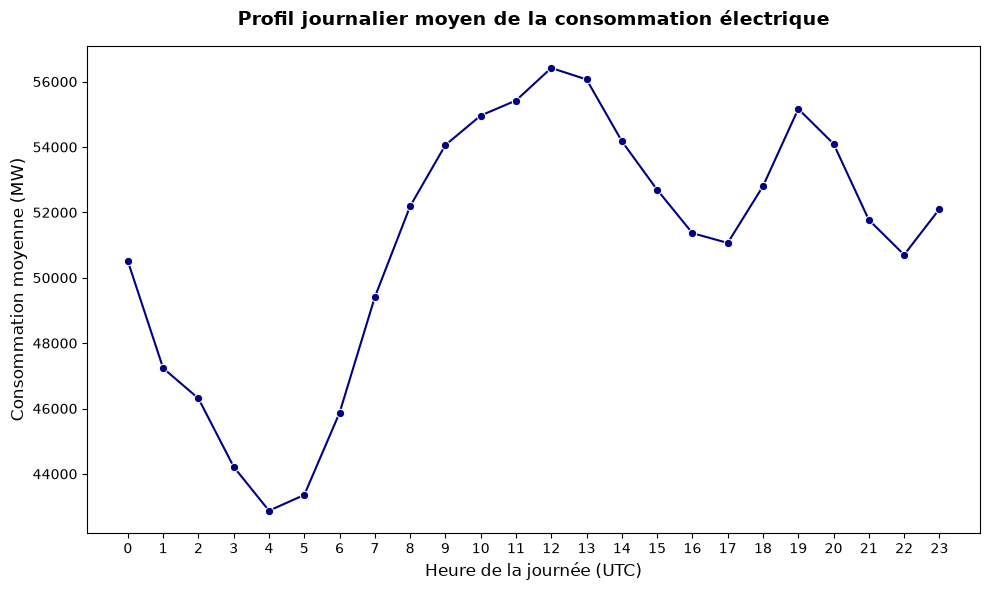

In [16]:
# Étape 1 : Calcul de la consommation moyenne pour chaque heure (de 0 à 23)
conso_moyenne_heure = df_rte_clean.groupby('Heure')['consommation'].mean()

# Étape 2 : Création du graphique avec matplotlib et seaborn
plt.figure(figsize=(10, 6))
sns.lineplot(x=conso_moyenne_heure.index, y=conso_moyenne_heure.values, marker="o", color="navy")

# Étape 3 : Personnalisation esthétique et clarté (critère d'évaluation)
plt.title("Profil journalier moyen de la consommation électrique", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Heure de la journée (UTC)", fontsize=12)
plt.ylabel("Consommation moyenne (MW)", fontsize=12)
plt.xticks(range(0, 24)) # Force l'affichage de chaque heure sur l'axe des abscisses

# Affichage du résultat
plt.tight_layout()
plt.show()

Ce graphique met en évidence la forte saisonnalité durant une journée pour la demande d'électricité. On observe 3 phases distinctes :
1. Le creux nocturne : La consommation atteint son minimum autour de 4h du matin, ainsi lorsque l'activité est au plus bas
2. Le pic de midi : La demande augmente fortement avec le réveil avec ensuite le début de l'activité industrielle et ou tertiaire. On observe alors un premier pic vers 12h.
3. Le pic du soir : Après le pic du midi, on observe une baisse durant l'après-midi. Par la suite on observe un second pic marqué à 19h. Cela correspond au retour des ménages dans leur foyer (Chauffage, Éclairage, Appareils électroménagers).

(L'heure étant en UTC, il ne faut pas oublier que pour trouver l'heure française il faut rajouter respectivement 1h en hiver et 2h en été)

## Analyse saisonnière
La France étant fortement équipée en chauffage électrique, la demande énergétique est très sensible aux variations de température. On va alors observer la consommaiton moyenne mensuelle.

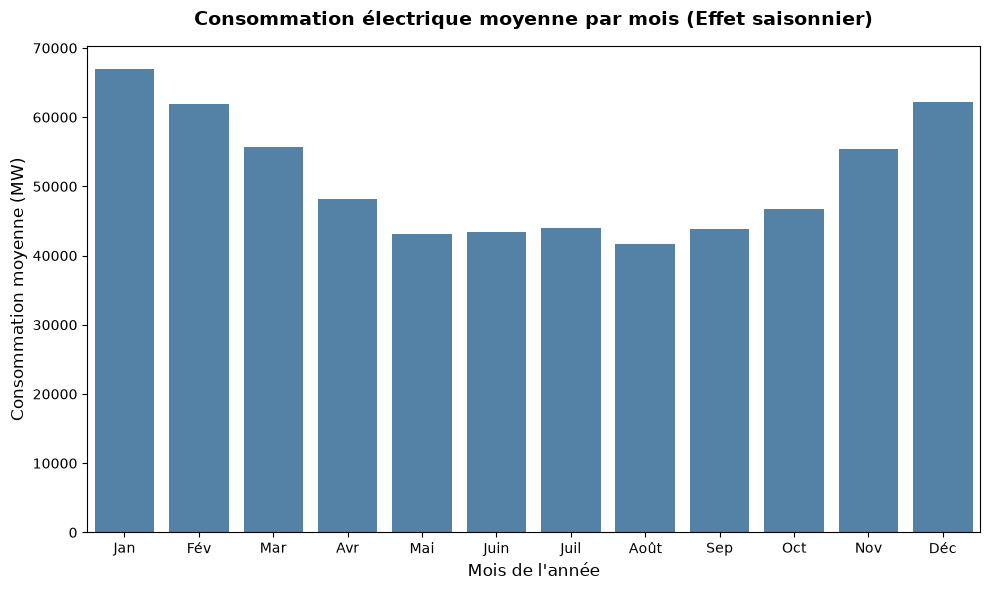

In [17]:
# Étape 1 : Calcul de la consommation moyenne pour chaque mois (de 1 à 12)
conso_moyenne_mois = df_rte_clean.groupby('Mois')['consommation'].mean()

# Étape 2 : Création du graphique en barres
plt.figure(figsize=(10, 6))
# On utilise seaborn pour un rendu propre, la couleur 'steelblue' reste sobre et académique
sns.barplot(x=conso_moyenne_mois.index, y=conso_moyenne_mois.values, color="steelblue")

# Étape 3 : Personnalisation (Titres, labels et remplacement des numéros par le nom des mois)
plt.title("Consommation électrique moyenne par mois (Effet saisonnier)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Mois de l'année", fontsize=12)
plt.ylabel("Consommation moyenne (MW)", fontsize=12)

mois_labels = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']
plt.xticks(ticks=range(12), labels=mois_labels)

plt.tight_layout()
plt.show()

## Interprétation de la saisonnalité 

Le graphique confirme une forte thermosensibilité de la consommation électrique française. On y observe un pic hivernal (Décembre, Janvier, Févrrier) et un creux estival (Mai, Juin, Juillet, Août, Septembre). 

## Dynamique des énergies renouvelables

Pour comprendre les déséquilibres du réseau, il faut croiser la demande avec la production fatale (qu'on ne peut pas piloter). Regardons précisément la saisonnalité pour l'éolien et le solaire.

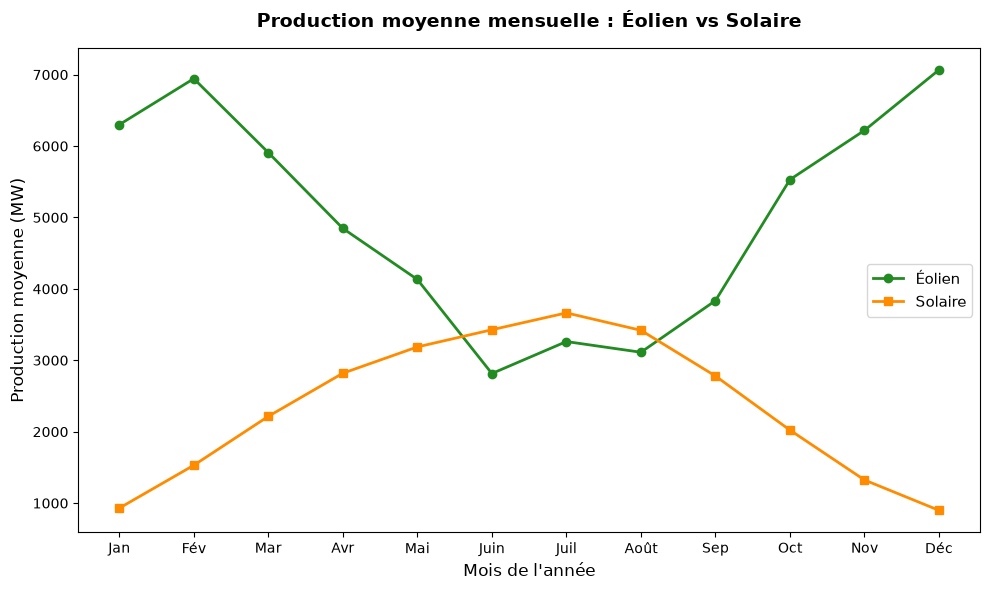

In [18]:
# Étape 1 : Calcul de la production moyenne pour chaque mois
prod_renouvelable_mois = df_rte_clean.groupby('Mois')[['eolien', 'solaire']].mean()

# Étape 2 : Création du graphique avec deux courbes superposées
plt.figure(figsize=(10, 6))

# Tracé de l'éolien (en vert) et du solaire (en orange)
plt.plot(prod_renouvelable_mois.index, prod_renouvelable_mois['eolien'], marker='o', label='Éolien', color='forestgreen', linewidth=2)
plt.plot(prod_renouvelable_mois.index, prod_renouvelable_mois['solaire'], marker='s', label='Solaire', color='darkorange', linewidth=2)

# Étape 3 : Personnalisation
plt.title("Production moyenne mensuelle : Éolien vs Solaire", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Mois de l'année", fontsize=12)
plt.ylabel("Production moyenne (MW)", fontsize=12)

# Reprise des mêmes labels pour garder la cohérence avec le graphique précédent
mois_labels = ['Jan', 'Fév', 'Mar', 'Avr', 'Mai', 'Juin', 'Juil', 'Août', 'Sep', 'Oct', 'Nov', 'Déc']
plt.xticks(ticks=range(1, 13), labels=mois_labels)

plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Inteprétation

Les deux sources d'énergies renouvelables présentent deux profils saisonniers opposés :
1. Le solaire suite logiquement une courbe en cloche inversée par rapport à la consommation, avec un pic de production en été car c'est là où on trouve un ensoleillement maximal.
2. L'éolien est beaucoup plus fort en hiver en raison des dépressions météorologiques plus fréquentes, ce qui coïncide avec la demande hivernale.

## Analyse de la charge résiduelle et risque de surproduction

La charge résiduelle est le principal moteur des prix sur le marché de gros. Une charge résiduelle faible, voire négative, indique que la production renouvelable couvre presque ou totalement la demande du pays, ce qui favorise l'apparition de prix négatifs.

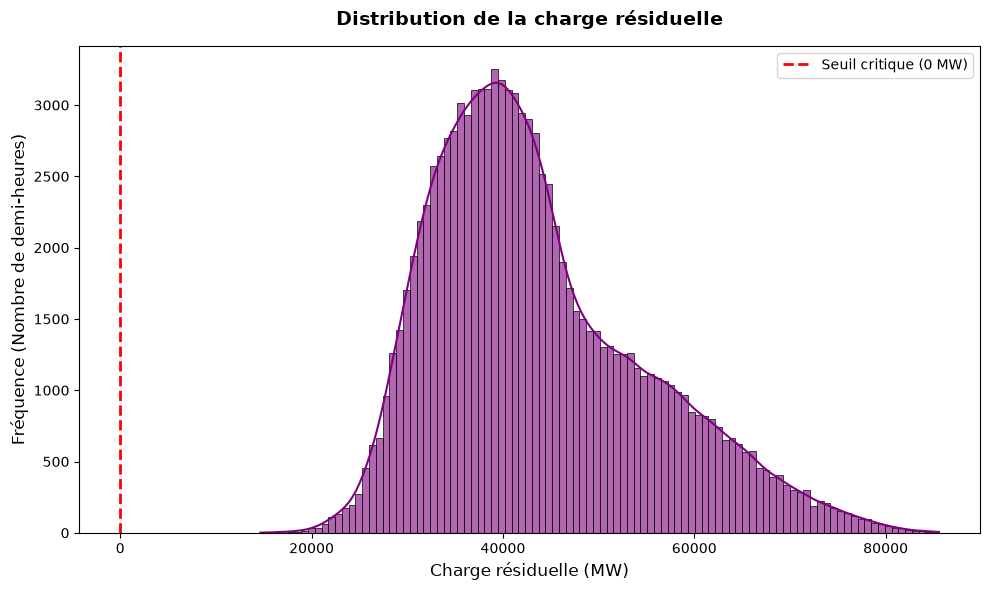

In [19]:
# Création de la figure
plt.figure(figsize=(10, 6))

# Tracé de l'histogramme avec une courbe de densité (KDE)
sns.histplot(df_rte_clean['charge_residuelle_mw'], bins=100, kde=True, color='purple', alpha=0.6)

# Ajout d'une ligne verticale rouge critique pour marquer le seuil de 0 MW
plt.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Seuil critique (0 MW)')

# Personnalisation
plt.title("Distribution de la charge résiduelle", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Charge résiduelle (MW)", fontsize=12)
plt.ylabel("Fréquence (Nombre de demi-heures)", fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

## Interprétation 

Cet histogramme permet de repérer la zone de tension pour le réseau. La majorité du temps, la charge résiduelle est largement positive. La queue de distribution à gauche montre les moments où cette charge s'approche de zéro, c'est dans ces épisodes qu'il peut y avoir des prix négatifs. Ici on observe clairement dans le jeu de données que la charge résiduelle ne descend jamais en dessous de 15000 MW, cela s'explique par le fait qu'en France la production éolienne et solaire cumulée n'est pas encore suffisante pour dépasser la consommation nationale. Les prix négatifs ne surviennent donc pas parce que la charge résiduelle est négative mais lorsqu'elle est très basse et que la production nucléaire est impossible à baisser pour diverses raisons. 

## Identification des épisodes de tension 

On va ainsi isoler les 10 demi-heures les plus critiques pour la charge résiduelle.

In [20]:
# On utilise la méthode 'nsmallest' de Pandas pour trouver les 15 valeurs les plus basses
episodes_critiques = df_rte_clean.nsmallest(15, 'charge_residuelle_mw')

# On sélectionne uniquement les colonnes pertinentes pour ne pas surcharger l'affichage
colonnes_a_voir = ['consommation', 'eolien', 'solaire', 'charge_residuelle_mw', 'Jour_semaine', 'Mois']

print("--- Les 15 des moments avec la plus faible charge résiduelle ---")
display(episodes_critiques[colonnes_a_voir])

--- Les 15 des moments avec la plus faible charge résiduelle ---


,consommation,eolien,solaire,charge_residuelle_mw,Jour_semaine,Mois
date_heure_utc,,,,,,
2023-08-06 16:00:00+02:00,36391.0,11892.0,9841.0,14658.0,6,8
2023-08-06 16:30:00+02:00,35962.0,11879.0,9202.0,14881.0,6,8
2023-08-06 15:30:00+02:00,37160.0,11943.0,10154.0,15063.0,6,8
2023-08-06 15:00:00+02:00,37661.0,11854.0,10520.0,15287.0,6,8
2023-08-06 17:00:00+02:00,35771.0,11581.0,8424.0,15766.0,6,8
2023-08-06 14:30:00+02:00,38492.0,11864.0,10615.0,16013.0,6,8
2023-08-06 14:00:00+02:00,39282.0,11861.0,10719.0,16702.0,6,8
2023-08-05 16:00:00+02:00,39258.0,14183.0,8289.0,16786.0,5,8
2023-08-06 05:00:00+02:00,29968.0,13164.0,0.0,16804.0,6,8


## Analyse des extrêmes 

En observant le tableau ci-dessus, on remarque que les moments de plus faible charge résiduelle partagent des caractéristiques communes : Jour_semaine = 5 ou 6 Mois = 8 ce qui correspond aux jours du week-end d'Août lorsque la consommation industrielle est faible mais que la production renouvelable est importante.